# Modelo SVR — Estimador de área cosechada (EVA)

**Inteligencia Artificial I — Grupo C2, 2026-2**

Modelo: **SVR (Support Vector Regression) con kernel RBF**, entrenado en **GPU** (Colab, cuML).
Variable objetivo: `area_cosechada` (ha). Se entrena y evalúa con **todas** las filas de cada conjunto.

| Conjunto | Años | Uso |
|---|---|---|
| Entrenamiento | 2007–2021 (sin 2018) | Ajustar el modelo |
| Validación | 2022 | Elegir hiperparámetros |
| Prueba (testing) | 2023–2025 | Evaluar **una sola vez** al final |

**Fases del notebook**
1. **Entrenamiento:** pruebas **manuales** de hiperparámetros (`C`, `gamma`, `epsilon`). Cada corrida se agrega a las gráficas del WAPE.
2. **Validación:** el modelo con los hiperparámetros elegidos se evalúa en 2022 con las 5 métricas.
3. **Testing:** el modelo final se reentrena con 2007–2022 y se evalúa en 2023–2025.

**Métricas:** MSE, RMSE, MAE, WAPE (principal) y R².

> Antes de ejecutar: *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*.

## 0. Preparación (GPU y librerías)

In [ ]:
# =========================================================
# PASO G0: Activar la aceleracion por GPU (Opcion A)
# =========================================================
# Debe ejecutarse ANTES de importar scikit-learn (primera celda del notebook).
%load_ext cuml.accel
!nvidia-smi -L
print("PASO G0: Ejecutado correctamente")

GPU 0: Tesla T4 (UUID: GPU-4c285288-8b03-130a-b8c6-ae45e05d9413)
PASO G0: Ejecutado correctamente


In [ ]:
# =========================================================
# Librerias que vamos a usar
# =========================================================
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.svm import SVR                  # con %load_ext cuml.accel corre en la GPU
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Estilo de las graficas (colores y tamanio por defecto)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["font.size"] = 11

VERDE = "#2a9d8f"
NARANJA = "#e76f51"
AZUL = "#264653"

# Para ver bien las tablas
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

print("Librerias cargadas correctamente")

Librerias cargadas correctamente


## 1. Limpieza de datos

In [ ]:
# =====================================================================
# LIMPIEZA DEFINITIVA DE LOS ARCHIVOS EVA (2007-2018 y 2019-2025)
# Resultado: la tabla "datos" con UNA fila por municipio + cultivo +
# estado fisico + anio, lista para entrenar los modelos.
# =====================================================================

import pandas as pd
import numpy as np

# =========================================================
# PASO 1: Cargar los dos archivos desde Google Drive
# =========================================================
print("PASO 1: Cargar los dos archivos desde Google Drive")
# Los archivos deben estar guardados en:  MiUnidad / EVA /
from google.colab import drive
drive.mount("/content/drive")

RUTA = "/content/drive/MyDrive/EVA/"

# Leemos todo como texto: los numeros vienen en formato colombiano
# ("1.247.206,27") y los codigos DANE tienen ceros a la izquierda ("05001").
eva_viejo = pd.read_csv(RUTA + "EVA_2007_2018.csv", dtype=str)
eva_nuevo = pd.read_csv(RUTA + "EVA_2019_2025.csv", dtype=str)

print("EVA 2007-2018:", eva_viejo.shape[0], "filas y", eva_viejo.shape[1], "columnas")
print("EVA 2019-2025:", eva_nuevo.shape[0], "filas y", eva_nuevo.shape[1], "columnas")
print("PASO 1: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
# =========================================================
print("PASO 2: Dejar solo las columnas necesarias, con el mismo nombre")

# El archivo viejo trae saltos de linea dentro de los nombres
# ("Área Sembrada\n(ha)"): los cambiamos por un espacio.
eva_viejo.columns = [" ".join(nombre.split()) for nombre in eva_viejo.columns]
eva_nuevo.columns = [" ".join(nombre.split()) for nombre in eva_nuevo.columns]

# Solo columnas que existen en LOS DOS archivos y que se usan despues.
# (El rendimiento no se carga: se recalcula al final con la formula.)
nombres_nuevo = {
    "Código Dane departamento":  "cod_dep",
    "Departamento":              "departamento",
    "Código Dane municipio":     "cod_mun",
    "Municipio":                 "municipio",
    "Grupo cultivo":             "grupo",
    "Cultivo":                   "cultivo",
    "Desagregación cultivo":     "desagregacion",
    "Año":                       "anio",
    "Periodo":                   "periodo",
    "Área sembrada":             "area_sembrada",
    "Área cosechada":            "area_cosechada",
    "Producción":                "produccion",
    "Ciclo del cultivo":         "ciclo",
    "Estado físico del cultivo": "estado_fisico",
}
nombres_viejo = {
    "CÓD. DEP.":                                     "cod_dep",
    "DEPARTAMENTO":                                  "departamento",
    "CÓD. MUN.":                                     "cod_mun",
    "MUNICIPIO":                                     "municipio",
    "GRUPO DE CULTIVO":                              "grupo",
    "CULTIVO":                                       "cultivo",
    "DESAGREGACIÓN REGIONAL Y/O SISTEMA PRODUCTIVO": "desagregacion",
    "AÑO":                                           "anio",
    "PERIODO":                                       "periodo",
    "Área Sembrada (ha)":                            "area_sembrada",
    "Área Cosechada (ha)":                           "area_cosechada",
    "Producción (t)":                                "produccion",
    "CICLO DE CULTIVO":                              "ciclo",
    "ESTADO FISICO PRODUCCION":                      "estado_fisico",
}
COLUMNAS = list(nombres_nuevo.values())
eva_nuevo = eva_nuevo.rename(columns=nombres_nuevo)[COLUMNAS].copy()
eva_viejo = eva_viejo.rename(columns=nombres_viejo)[COLUMNAS].copy()

print("Columnas que se conservan:", COLUMNAS)
print("PASO 2: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 3: Convertir los numeros y los codigos DANE
# =========================================================
print("PASO 3: Convertir los numeros y los codigos DANE")

def convertir_a_numero(columna):
    # "1.247.206,27" -> 1247206.27  (el punto separa miles, la coma es decimal)
    texto = columna.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")

for df in (eva_viejo, eva_nuevo):
    for columna in ["anio", "area_sembrada", "area_cosechada", "produccion"]:
        df[columna] = convertir_a_numero(df[columna])
    df["anio"] = df["anio"].astype(int)
    # Codigos: "15.114" -> "15114"  y  "5.001" -> "05001"
    df["cod_dep"] = df["cod_dep"].str.replace(".", "", regex=False).str.zfill(2)
    df["cod_mun"] = df["cod_mun"].str.replace(".", "", regex=False).str.zfill(5)

# Controles: ningun numero vacio, ningun negativo, codigos coherentes
for nombre, df in [("2007-2018", eva_viejo), ("2019-2025", eva_nuevo)]:
    numeros = df[["area_sembrada", "area_cosechada", "produccion"]]
    assert numeros.notna().all().all(), "Hay numeros que no se pudieron convertir en " + nombre
    assert (numeros >= 0).all().all(), "Hay numeros negativos en " + nombre
    assert (df["cod_mun"].str[:2] == df["cod_dep"]).all(), "Codigos inconsistentes en " + nombre

print("PASO 3: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 4: Poner el texto en mayusculas y sin tildes
# =========================================================
print("PASO 4: Poner el texto en mayusculas y sin tildes")

def limpiar_texto(columna):
    texto = columna.str.upper().str.strip()
    texto = texto.str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8")
    return texto.str.replace(r"\s+", " ", regex=True)   # espacios dobles -> uno

for df in (eva_viejo, eva_nuevo):
    for columna in ["departamento", "municipio", "grupo", "cultivo",
                    "desagregacion", "ciclo", "estado_fisico"]:
        df[columna] = limpiar_texto(df[columna])

print("PASO 4: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 5: Estandarizar los nombres de cultivo y de estado fisico
# =========================================================
# Regla: solo se unifica lo que es el MISMO cultivo. Lo que es distinto
# se deja separado, y si queda solo en un archivo se elimina en el PASO 6.
print("PASO 5: Estandarizar los nombres de cultivo y de estado fisico")

# 5.1 El archivo nuevo junta las tres canas en "CANA", pero la desagregacion
#     las separa. Como son productos distintos, las separamos igual que el viejo.
es_cana = eva_nuevo["cultivo"] == "CANA"
eva_nuevo.loc[es_cana, "cultivo"] = eva_nuevo.loc[es_cana, "desagregacion"]
eva_nuevo["cultivo"] = eva_nuevo["cultivo"].replace({"CANA DE AZUCAR": "CANA AZUCARERA",
                                                     "ESTEVIA": "STEVIA"})

# 5.2 Nombres del archivo viejo que se pasan al nombre del archivo nuevo.
cultivos_equivalentes = {
    # a) El mismo cultivo, solo cambio el nombre
    "DURAZNO":     "DURAZNO O ALBARICOQUE",
    "AGRAZ":       "AGRAZ - MORTINO",
    "PEPA DE PAN": "ARBOL DE PAN O PEPA DEL PAN",
    "PAPAYUELA":   "PAPAYUELA -BABACO",
    "CURCUMA":     "CURCUMA O AZAFRAN",
    "RUBA":        "ULLUCO",
    # b) El archivo nuevo definio una categoria que junta exactamente
    #    los cultivos que el viejo traia separados
    "GULUPA":      "GULUPA O CHOLUPA",
    "CHOLUPA":     "GULUPA O CHOLUPA",
    "CALABACIN":   "CALABACIN, CALABAZA",
    "CALABAZA":    "CALABACIN, CALABAZA",
    "MALANGA":     "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
    "BORE":        "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
}
eva_viejo["cultivo"] = eva_viejo["cultivo"].replace(cultivos_equivalentes)

# 5.3 Estado fisico: se unifican solo los nombres que significan lo mismo.
#     Lo demas se deja como viene (ej. PANELA y CANA O VERDE son distintos).
estados_equivalentes = {
    "FRUTO FRESCO":       "EN FRESCO",
    "HORTALIZA FRESCA":   "EN FRESCO",
    "TUBERCULO FRESCO":   "EN FRESCO",
    "HOJA FRESCA":        "EN FRESCO",
    "LEGUMINOSA FRESCA":  "EN FRESCO",
    "PADDY VERDE":        "PADDY O CASCARA VERDE",
    "SEMILLA":            "ALGODON SEMILLA",
    "CANA PARA MOLIENDA": "CANA O VERDE",
}
eva_viejo["estado_fisico"] = eva_viejo["estado_fisico"].replace(estados_equivalentes)

print("PASO 5: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos
# =========================================================
print("PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos")

# 6.1 Nos quedamos solo con los cultivos que aparecen en LOS DOS archivos
cultivos_comunes = set(eva_viejo["cultivo"]) & set(eva_nuevo["cultivo"])
eliminados = (pd.concat([eva_viejo, eva_nuevo])
                .loc[lambda df: ~df["cultivo"].isin(cultivos_comunes)]
                .groupby("cultivo")["area_cosechada"].sum()
                .sort_values(ascending=False))
print("Cultivos que estan en un solo archivo (se eliminan):", len(eliminados))
print("Los 10 con mas area cosechada:")
print(eliminados.head(10).round(0))

eva_viejo = eva_viejo[eva_viejo["cultivo"].isin(cultivos_comunes)].copy()
eva_nuevo = eva_nuevo[eva_nuevo["cultivo"].isin(cultivos_comunes)].copy()

# 6.2 Catalogo: grupo y ciclo de cada cultivo segun el archivo nuevo
#     (ahi cada cultivo tiene un solo grupo y un solo ciclo)
catalogo = eva_nuevo.groupby("cultivo")[["grupo", "ciclo"]].first()
assert (eva_nuevo.groupby("cultivo")["grupo"].nunique() == 1).all()
assert (eva_nuevo.groupby("cultivo")["ciclo"].nunique() == 1).all()

# 6.3 El archivo viejo toma el grupo y el ciclo del catalogo
eva_viejo["grupo"] = eva_viejo["cultivo"].map(catalogo["grupo"])
eva_viejo["ciclo"] = eva_viejo["cultivo"].map(catalogo["ciclo"])

print("Cultivos que quedan:", len(cultivos_comunes))
print("Grupos:", sorted(catalogo["grupo"].unique()))
print("PASO 6: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018
# =========================================================
print("PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018")

eva_viejo["fuente"] = "2007-2018"
eva_nuevo["fuente"] = "2019-2025"
datos = pd.concat([eva_viejo, eva_nuevo], ignore_index=True)

# Nombres oficiales a partir del codigo DANE (se usa el del archivo nuevo).
# Asi un municipio no aparece con dos nombres ("DON MATIAS" / "DONMATIAS").
for codigo, nombre in [("cod_dep", "departamento"), ("cod_mun", "municipio")]:
    nombre_oficial = datos.sort_values("fuente").groupby(codigo)[nombre].last()
    datos[nombre] = datos[codigo].map(nombre_oficial)

# 2006: solo trae el semestre B.  2018: no trae el semestre B.
# Los dos anios estan incompletos y sesgarian los totales anuales.
print("Filas del 2006:", (datos["anio"] == 2006).sum())
print("Filas del 2018:", (datos["anio"] == 2018).sum())
datos = datos[~datos["anio"].isin([2006, 2018])]

print("Filas despues de unir:", len(datos))
print("PASO 7: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 8: Pasar de semestres a anios (suma simple)
# =========================================================
# Se suman los semestres A y B y las variedades (desagregaciones) de cada
# cultivo. La produccion solo se suma entre filas con el MISMO estado fisico,
# por eso el estado fisico es parte de la clave (ej. maiz en grano seco y
# maiz en fresco quedan en filas separadas).
print("PASO 8: Pasar de semestres a anios (suma simple)")

CLAVE = ["cod_mun", "cultivo", "estado_fisico", "anio"]
datos = (datos.groupby(CLAVE, as_index=False)
              .agg(fuente=("fuente", "first"),
                   cod_dep=("cod_dep", "first"),
                   departamento=("departamento", "first"),
                   municipio=("municipio", "first"),
                   grupo=("grupo", "first"),
                   ciclo=("ciclo", "first"),
                   area_sembrada=("area_sembrada", "sum"),
                   area_cosechada=("area_cosechada", "sum"),
                   produccion=("produccion", "sum")))

# Rendimiento recalculado con la formula (vacio si no hubo cosecha)
datos["rendimiento"] = np.where(datos["area_cosechada"] > 0,
                                datos["produccion"] / datos["area_cosechada"], np.nan)

print("Filas anuales:", len(datos))
print("PASO 8: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 9: Regla de arrastre (sin tolerancia) y consistencia
# =========================================================
# En los cultivos TRANSITORIOS, lo sembrado y no cosechado un anio puede
# cosecharse al anio siguiente (solo se arrastra UN anio):
#     area_pendiente_anterior = sembrada(anio-1) - cosechada(anio-1)   (si es > 0)
#     area_disponible         = sembrada(anio) + area_pendiente_anterior
# En los PERMANENTES no hay arrastre (el area sembrada ya es todo lo plantado).
# Se elimina toda fila que coseche mas que el area disponible.
print("PASO 9: Regla de arrastre (sin tolerancia) y consistencia")

datos = datos.sort_values(CLAVE).reset_index(drop=True)
serie = datos.groupby(["cod_mun", "cultivo", "estado_fisico"])
sembrada_ant = serie["area_sembrada"].shift(1)
cosechada_ant = serie["area_cosechada"].shift(1)
anio_ant = serie["anio"].shift(1)

# Solo hay arrastre si existe el anio inmediatamente anterior y es transitorio
hay_arrastre = (datos["anio"] - anio_ant == 1) & (datos["ciclo"] == "TRANSITORIO")
datos["area_pendiente_anterior"] = np.where(hay_arrastre,
                                            (sembrada_ant - cosechada_ant).clip(lower=0), 0.0)
area_disponible = datos["area_sembrada"] + datos["area_pendiente_anterior"]

regla_arrastre = datos["area_cosechada"] > area_disponible        # cosecho mas de lo disponible
regla_produccion = (datos["produccion"] > 0) & (datos["area_cosechada"] == 0)   # produccion sin cosecha
sin_area = area_disponible == 0                                    # nada sembrado ni pendiente

print("Cosecharon mas que el area disponible:", regla_arrastre.sum())
print("Produccion sin area cosechada        :", regla_produccion.sum())
print("Sin area sembrada ni pendiente       :", sin_area.sum())
datos = datos[~(regla_arrastre | regla_produccion | sin_area)].reset_index(drop=True)

print("Filas que quedan:", len(datos))
print("PASO 9: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 10: Agregar la altura de cada municipio (msnm)
# =========================================================
# Fuente: IGAC, publicada en el Panel Municipal del CEDE (Universidad de los
# Andes), archivo "PANEL_CARACTERISTICAS_GENERALES_2021.csv" guardado en la
# misma carpeta de Drive. Columnas usadas: codmpio (codigo DANE) y altura (msnm).
print("PASO 10: Agregar la altura de cada municipio (msnm)")

ARCHIVO_ALTURA = RUTA + "PANEL_CARACTERISTICAS_GENERALES_2021.csv"
altura = pd.read_csv(ARCHIVO_ALTURA, usecols=["codmpio", "altura"], encoding="latin-1")

# El panel trae una fila por anio, pero la altura de un municipio no cambia:
# nos quedamos con una sola fila por municipio.
altura = altura.dropna(subset=["altura"]).drop_duplicates(subset="codmpio")
altura["cod_mun"] = altura["codmpio"].astype(int).astype(str).str.zfill(5)   # 5001 -> "05001"
altura = altura.rename(columns={"altura": "altura_msnm"})[["cod_mun", "altura_msnm"]]

# Municipios que no estan en el panel (creados despues): altura aproximada a mano
altura_manual = pd.DataFrame({
    "cod_mun":     ["27493"],     # NUEVO BELEN DE BAJIRA (Choco)
    "altura_msnm": [105],
})
altura = pd.concat([altura, altura_manual], ignore_index=True)

datos = datos.merge(altura, on="cod_mun", how="left")

print("PASO 10: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 11: Revision final y orden de columnas
# =========================================================
print("PASO 11: Revision final y orden de columnas")

# La clave debe ser unica: una fila por municipio + cultivo + estado + anio
assert not datos.duplicated(CLAVE).any(), "Hay filas repetidas en la clave"

COLUMNAS_FINALES = ["anio", "fuente", "cod_dep", "departamento", "cod_mun", "municipio",
                    "altura_msnm", "grupo", "cultivo", "ciclo", "estado_fisico",
                    "area_sembrada", "area_pendiente_anterior", "area_cosechada",
                    "produccion", "rendimiento"]
datos = datos[COLUMNAS_FINALES]

print("Filas:", len(datos), "| Columnas:", datos.shape[1])
print("Anios:", sorted(datos["anio"].unique()))
print("Departamentos:", datos["cod_dep"].nunique(), "| Municipios:", datos["cod_mun"].nunique(),
      "| Cultivos:", datos["cultivo"].nunique(), "| Grupos:", datos["grupo"].nunique())
print()
print("Datos faltantes por columna:")
print(datos.isna().sum()[datos.isna().sum() > 0])
print("(el rendimiento queda vacio solo cuando el area cosechada es 0)")
print()
print("Filas por grupo y archivo:")
print(pd.crosstab(datos["grupo"], datos["fuente"]))
print()
# Cultivos cuyo estado fisico cambia entre archivos (su produccion no se compara)
estados = datos.groupby(["cultivo", "fuente"])["estado_fisico"].apply(lambda s: " / ".join(sorted(s.unique())))
estados = estados.unstack()
cambian = estados[estados["2007-2018"] != estados["2019-2025"]]
print("Cultivos cuyo estado fisico cambia entre archivos:", len(cambian))
print(cambian)
print("PASO 11: Ejecutado correctamente")
print("-------------------------------")

# Para guardar (al leerlo de nuevo, usar dtype={"cod_dep": str, "cod_mun": str}):
# datos.to_csv(RUTA + "eva_limpio.csv", index=False, encoding="utf-8-sig")
datos.to_csv("/content/drive/MyDrive/EVA/eva_limpio.csv", index=False)

datos.head()


PASO 1: Cargar los dos archivos desde Google Drive
Mounted at /content/drive
EVA 2007-2018: 206068 filas y 17 columnas
EVA 2019-2025: 166732 filas y 18 columnas
PASO 1: Ejecutado correctamente
-------------------------------
PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
Columnas que se conservan: ['cod_dep', 'departamento', 'cod_mun', 'municipio', 'grupo', 'cultivo', 'desagregacion', 'anio', 'periodo', 'area_sembrada', 'area_cosechada', 'produccion', 'ciclo', 'estado_fisico']
PASO 2: Ejecutado correctamente
-------------------------------
PASO 3: Convertir los numeros y los codigos DANE
PASO 3: Ejecutado correctamente
-------------------------------
PASO 4: Poner el texto en mayusculas y sin tildes
PASO 4: Ejecutado correctamente
-------------------------------
PASO 5: Estandarizar los nombres de cultivo y de estado fisico
PASO 5: Ejecutado correctamente
-------------------------------
PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos
Cu

,anio,fuente,cod_dep,departamento,cod_mun,municipio,altura_msnm,grupo,cultivo,ciclo,estado_fisico,area_sembrada,area_pendiente_anterior,area_cosechada,produccion,rendimiento
0,2007,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.000",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.000,0.000,0.000,0.000,NaN
1,2008,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.000",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.000,0.000,0.000,0.000,NaN
2,2009,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.000",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,12.000,0.000,6.000,36.000,6.000
3,2010,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.000",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,16.000,0.000,10.000,60.000,6.000
4,2011,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.000",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,19.000,0.000,16.000,96.000,6.000


## 2. Bloque común (features, división por años y métricas)

| Paso | Qué hace |
|---|---|
| C1 | Construye las features a partir de la tabla limpia (`datos`) |
| C2 | Divide por años: entrenamiento 2007–2021, validación 2022, prueba 2023–2025 |
| C3 | Funciones de evaluación: las 5 métricas y el formato de salida común del equipo |

In [ ]:
# =========================================================
# PASO C1: Construir las features
# =========================================================
# Todas salen de columnas de la tabla limpia. Cada serie es un
# municipio + cultivo + estado fisico a lo largo de los anios.
print("PASO C1: Construir las features")

# --- Valores fijos del proyecto (iguales para los 4 modelos) ---
SEMILLA = 42
ANIO_FIN_ENTRENO = 2021              # entrenamiento: 2007-2021 (sin 2018)
ANIO_VALIDACION = 2022               # validacion: elegir hiperparametros
ANIOS_PRUEBA = [2023, 2024, 2025]    # prueba: se evalua UNA sola vez al final

SERIE = ["cod_mun", "cultivo", "estado_fisico"]
df = datos.sort_values(SERIE + ["anio"]).reset_index(drop=True)

# Area que habia para cosechar (sembrada + pendiente del anio anterior)
df["area_disponible"] = df["area_sembrada"] + df["area_pendiente_anterior"]

# Datos del anio anterior de la misma serie (0 si no existe ese anio)
serie = df.groupby(SERIE)
anio_ant = serie["anio"].shift(1)
df["hay_ant"] = ((df["anio"] - anio_ant) == 1).astype(int)
df["cosechada_ant"] = np.where(df["hay_ant"] == 1, serie["area_cosechada"].shift(1), 0)
df["sembrada_ant"] = np.where(df["hay_ant"] == 1, serie["area_sembrada"].shift(1), 0)

# Tasa historica: promedio de (cosechada / disponible) en los anios ANTERIORES de la serie
df["tasa_real"] = df["area_cosechada"] / df["area_disponible"]
df["tasa_hist"] = serie["tasa_real"].transform(lambda s: s.shift(1).expanding().mean())
df["hay_hist"] = df["tasa_hist"].notna().astype(int)

# Columnas de texto pasadas a 0/1
df["permanente"] = (df["ciclo"] == "PERMANENTE").astype(int)
df["rep2019"] = (df["fuente"] == "2019-2025").astype(int)

# Logaritmos: las areas van de menos de 1 ha a mas de 100.000 ha
for col in ["area_sembrada", "area_disponible", "cosechada_ant", "sembrada_ant"]:
    df["log_" + col] = np.log1p(df[col])

print("Filas:", len(df))
print("PASO C1: Ejecutado correctamente")
print("-------------------------------")

PASO C1: Construir las features
Filas: 238350
PASO C1: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO C2: Division por anios (nunca al azar)
# =========================================================
print("PASO C2: Division por anios")
entreno = df[df["anio"] <= ANIO_FIN_ENTRENO].copy()
validacion = df[df["anio"] == ANIO_VALIDACION].copy()
prueba = df[df["anio"].isin(ANIOS_PRUEBA)].copy()

print("Entrenamiento (2007-2021):", len(entreno))
print("Validacion (2022)        :", len(validacion))
print("Prueba (2023-2025)       :", len(prueba))
print("PASO C2: Ejecutado correctamente")
print("-------------------------------")

PASO C2: Division por anios
Entrenamiento (2007-2021): 176975
Validacion (2022)        : 15041
Prueba (2023-2025)       : 46334
PASO C2: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO C3: Funciones de evaluacion (iguales para los 4 modelos)
# =========================================================
print("PASO C3: Funciones de evaluacion")

def objetivo(tabla):
    return np.log1p(tabla["area_cosechada"].values)          # el modelo aprende log(1 + area)

def a_hectareas(pred_log, tabla):
    # Volver a hectareas y no pasar del area disponible
    return np.clip(np.expm1(pred_log), 0, tabla["area_disponible"].values)

def metricas(real, estimada):
    """Las 5 metricas del proyecto (en hectareas)."""
    mse = mean_squared_error(real, estimada)
    return {"MSE": mse,
            "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(real, estimada),
            "WAPE_%": np.abs(real - estimada).sum() / real.sum() * 100,
            "R2": r2_score(real, estimada)}

def tabla_resultados(tabla, estimada, nombre_modelo):
    """Metricas del modelo y de las 2 reglas base, total y por grupo."""
    reglas = {nombre_modelo: estimada,
              "Base: cosechada = sembrada": tabla["area_sembrada"].values,
              "Base: disponible x tasa historica": (tabla["area_disponible"] * tabla["tasa_hist"]).values}
    real = tabla["area_cosechada"].values
    filas = []
    for nombre, est in reglas.items():
        filas.append({"modelo": nombre, "grupo": "TOTAL", **metricas(real, est)})
        for g in sorted(tabla["grupo"].unique()):
            m = (tabla["grupo"] == g).values
            filas.append({"modelo": nombre, "grupo": g, **metricas(real[m], est[m])})
    return pd.DataFrame(filas)

def tabla_predicciones(tabla, estimada, nombre_modelo):
    """Predicciones en el formato comun del equipo, con la tasa de cosecha efectiva."""
    salida = tabla[["anio", "cod_mun", "municipio", "departamento", "grupo", "cultivo",
                    "estado_fisico", "area_sembrada", "area_disponible", "area_cosechada"]].copy()
    salida["area_cosechada_estimada"] = estimada
    sembrada = salida["area_sembrada"].replace(0, np.nan)
    salida["tasa_cosecha_real_%"] = salida["area_cosechada"] / sembrada * 100
    salida["tasa_cosecha_estimada_%"] = salida["area_cosechada_estimada"] / sembrada * 100
    salida["modelo"] = nombre_modelo
    return salida

print("PASO C3: Ejecutado correctamente")
print("-------------------------------")

PASO C3: Funciones de evaluacion
PASO C3: Ejecutado correctamente
-------------------------------


## 3. Modelo SVR

**M1** prepara los datos y define el pipeline del SVR:
- **Continuas** (`StandardScaler`): áreas en logaritmo, tasa histórica, altura y año.
- **Binarias** (0/1, sin cambios): `hay_ant`, `hay_hist`, `rep2019`, `permanente`.
- **Categóricas** (one-hot 0/1): `grupo`, `cultivo`, `cod_dep`.
- **SVR** con kernel RBF, en `float32` para que la GPU sea más rápida.

In [ ]:
# =========================================================
# PASO M1: Preparar los datos y definir el pipeline del SVR
# =========================================================
print("PASO M1: Preparar los datos y definir el pipeline del SVR")
NOMBRE_MODELO = "SVR"

def preparar(tabla_entreno, tabla, ultimo_anio):
    """Prepara 'tabla' usando solo informacion de 'tabla_entreno'."""
    t = tabla.copy()
    # 1) tasa_hist vacia -> promedio del cultivo en entrenamiento (o promedio general)
    tasa_cultivo = tabla_entreno.groupby("cultivo")["tasa_real"].mean()
    t["tasa_hist"] = t["tasa_hist"].fillna(t["cultivo"].map(tasa_cultivo))
    t["tasa_hist"] = t["tasa_hist"].fillna(tabla_entreno["tasa_real"].mean())
    # 2) Cultivos con menos de 100 filas de entrenamiento -> "OTROS"
    conteo = tabla_entreno["cultivo"].value_counts()
    cultivos_ok = conteo[conteo >= 100].index
    t["cultivo_mod"] = np.where(t["cultivo"].isin(cultivos_ok), t["cultivo"], "OTROS")
    # 3) Anio topado al ultimo anio de entrenamiento (los anios futuros entran como ese anio)
    t["anio_mod"] = t["anio"].clip(upper=ultimo_anio)
    return t

ent = preparar(entreno, entreno, ANIO_FIN_ENTRENO)
val = preparar(entreno, validacion, ANIO_FIN_ENTRENO)

CONTINUAS = ["log_area_sembrada", "log_area_disponible", "log_cosechada_ant",
             "log_sembrada_ant", "tasa_hist", "altura_msnm", "anio_mod"]   # -> StandardScaler
BINARIAS = ["hay_ant", "hay_hist", "rep2019", "permanente"]               # -> se quedan en 0/1
CATEGORIAS = ["grupo", "cultivo_mod", "cod_dep"]                          # -> one-hot 0/1

def crear_modelo(C, gamma, epsilon):
    """Pipeline: el escalador y el one-hot aprenden SOLO de los datos con que se entrena."""
    preparacion = ColumnTransformer([
        ("continuas", StandardScaler(), CONTINUAS),
        ("binarias", "passthrough", BINARIAS),
        ("categorias", OneHotEncoder(drop="first", handle_unknown="ignore"), CATEGORIAS),
    ], sparse_threshold=0)                                    # matriz densa para el SVR
    return Pipeline([
        ("preparacion", preparacion),
        ("float32", FunctionTransformer(lambda X: X.astype(np.float32))),   # mas rapido en GPU
        ("svr", SVR(kernel="rbf", C=C, gamma=gamma, epsilon=epsilon, cache_size=1000)),
    ])

print("Filas de entrenamiento:", len(ent), "| Filas de validacion:", len(val))
print("PASO M1: Ejecutado correctamente")
print("-------------------------------")

PASO M1: Preparar los datos y definir el pipeline del SVR
Filas de entrenamiento: 176975 | Filas de validacion: 15041
PASO M1: Ejecutado correctamente
-------------------------------


## Fase 1 — Entrenamiento (pruebas manuales de hiperparámetros)

Cada **corrida** entrena el SVR con **todas** las filas de 2007–2021 y mide el WAPE en el entrenamiento y en la validación (2022).

**Cómo usarla:**
1. Ejecutar **F1.2** una sola vez (carga las funciones y el registro de corridas).
2. Escribir los hiperparámetros en **F1.1** y ejecutar **F1.1** y **F1.3**.
3. Cambiar un hiperparámetro en F1.1 y volver a ejecutar F1.1 y F1.3. **Cada corrida se agrega a las gráficas**, que no se reinician.

El registro se guarda en Drive (`corridas_SVR.csv`), así que no se pierde si se reinicia la sesión. Para empezar de cero: `REINICIAR_REGISTRO = True` en F1.1, una sola vez.

| Hiperparámetro | Qué controla |
|---|---|
| `C` | Cuánto castiga el modelo los errores fuera del tubo. Alto = se ajusta más a los datos |
| `gamma` | Qué tan lejos llega la influencia de cada punto. Alto = curvas más "locales" |
| `epsilon` | Ancho del tubo de tolerancia (en escala log: 0,05 ≈ ±5% de error) |

**Gráficas de F1.3:**
- **Evolución de las corridas:** WAPE de cada corrida en el orden en que se hizo, con sus hiperparámetros.
- **Un hiperparámetro a la vez:** para la corrida actual, el WAPE según `C`, según `gamma` y según `epsilon`. Cada panel usa solo las corridas que tienen **los otros dos hiperparámetros iguales** a los de la corrida actual. Así se ve el efecto de cambiar solo ese hiperparámetro.

Si la línea de entrenamiento baja mientras la de validación sube, el modelo empieza a **sobreajustar**.

In [ ]:
# =========================================================
# PASO F1.1: Hiperparametros de la corrida  (EDITAR AQUI)
# =========================================================
print("PASO F1.1: Hiperparametros de la corrida")

C = 10              # castigo por salirse del tubo
# 10 bueno, 20 parecido.
GAMMA = 0.01       # alcance de la influencia de cada punto
# 0.1 overfitting con C=10 y malo con C=1.
EPSILON = 0.01      # ancho del tubo (0.05 ~ tolera +-5% de error)

REINICIAR_REGISTRO = False   # True = borra todas las corridas anteriores (usar una sola vez)

print("C =", C, "| gamma =", GAMMA, "| epsilon =", EPSILON)
print("PASO F1.1: Ejecutado correctamente")
print("-------------------------------")

PASO F1.1: Hiperparametros de la corrida
C = 20 | gamma = 0.01 | epsilon = 0.01
PASO F1.1: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO F1.2: Funciones y registro de corridas  (ejecutar UNA vez)
# =========================================================
print("PASO F1.2: Funciones y registro de corridas")
import os

ARCHIVO_REGISTRO = RUTA + "corridas_SVR.csv"

# Si ya hay corridas guardadas en Drive, se cargan para seguir agregando
if os.path.exists(ARCHIVO_REGISTRO):
    registro = pd.read_csv(ARCHIVO_REGISTRO)
else:
    registro = pd.DataFrame()
print("Corridas guardadas:", len(registro))

# Referencia: la regla "cosechada = sembrada" en validacion
WAPE_REGLA_VAL = metricas(val["area_cosechada"].values, val["area_sembrada"].values.astype(float))["WAPE_%"]

def entrenar_y_medir(C, gamma, epsilon):
    """Entrena con TODO el entrenamiento y mide en entrenamiento y validacion."""
    inicio = time.time()
    modelo = crear_modelo(C, gamma, epsilon)
    modelo.fit(ent, objetivo(ent))
    m_ent = metricas(ent["area_cosechada"].values, a_hectareas(modelo.predict(ent), ent))
    m_val = metricas(val["area_cosechada"].values, a_hectareas(modelo.predict(val), val))
    return {"C": C, "gamma": gamma, "epsilon": epsilon,
            "WAPE_entreno": m_ent["WAPE_%"], "WAPE_validacion": m_val["WAPE_%"],
            "MSE_validacion": m_val["MSE"], "RMSE_validacion": m_val["RMSE"],
            "MAE_validacion": m_val["MAE"], "R2_validacion": m_val["R2"],
            "segundos": round(time.time() - inicio)}

def txt(v):
    """Numero sin ceros sobrantes: 30.0 -> '30', 0.0030 -> '0.003'."""
    return "{:g}".format(v)

def graficar_evolucion(tabla):
    """WAPE de cada corrida, en el orden en que se hicieron."""
    x = range(1, len(tabla) + 1)
    plt.figure(figsize=(12, 5))
    plt.plot(x, tabla["WAPE_entreno"], marker="o", color=VERDE, label="Entrenamiento (2007-2021)")
    plt.plot(x, tabla["WAPE_validacion"], marker="o", color=NARANJA, label="Validacion (2022)")
    plt.axhline(WAPE_REGLA_VAL, color=AZUL, linestyle=":", label="Regla cosechada = sembrada (2022)")
    plt.scatter([len(tabla)], [tabla["WAPE_validacion"].iloc[-1]], s=200, color=NARANJA,
                edgecolor="black", zorder=5, label="Corrida actual")
    etiquetas = ["C=" + txt(f["C"]) + "\ng=" + txt(f["gamma"]) + "\ne=" + txt(f["epsilon"])
                 for _, f in tabla.iterrows()]
    plt.xticks(list(x), etiquetas, fontsize=8)
    plt.xlabel("Corrida (C = C, g = gamma, e = epsilon)")
    plt.ylabel("WAPE (%)")
    plt.title("Evolucion de las corridas")
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

def graficar_un_hiperparametro(tabla):
    """Para la corrida actual: WAPE segun cada hiperparametro, con los otros dos fijos."""
    actual = tabla.iloc[-1]
    figura, ejes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, nombre in zip(ejes, ["C", "gamma", "epsilon"]):
        otros = [h for h in ["C", "gamma", "epsilon"] if h != nombre]
        # corridas con los otros dos hiperparametros iguales a los de la corrida actual
        mismas = np.isclose(tabla[otros[0]], actual[otros[0]]) & np.isclose(tabla[otros[1]], actual[otros[1]])
        t = tabla[mismas].groupby(nombre, as_index=False)[["WAPE_entreno", "WAPE_validacion"]].mean()
        ax.plot(t[nombre], t["WAPE_entreno"], marker="o", color=VERDE, label="Entrenamiento")
        ax.plot(t[nombre], t["WAPE_validacion"], marker="o", color=NARANJA, label="Validacion (2022)")
        ax.axhline(WAPE_REGLA_VAL, color=AZUL, linestyle=":", label="Regla cosechada = sembrada")
        ax.axvline(actual[nombre], color="gray", linestyle="--", alpha=0.6, label="Valor actual")
        if nombre != "epsilon" and len(t) > 1:
            ax.set_xscale("log")
            ax.minorticks_off()                   # sin marcas intermedias de la escala log
        ax.set_xticks(t[nombre])
        ax.set_xticklabels([txt(v) for v in t[nombre]])
        ax.set_xlabel(nombre)
        ax.set_ylabel("WAPE (%)")
        ax.set_title("WAPE segun " + nombre + "\n(" + otros[0] + "=" + txt(actual[otros[0]]) +
                     ", " + otros[1] + "=" + txt(actual[otros[1]]) + ")")
        ax.legend(frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()

print("PASO F1.2: Ejecutado correctamente")
print("-------------------------------")

PASO F1.2: Funciones y registro de corridas
Corridas guardadas: 0
PASO F1.2: Ejecutado correctamente
-------------------------------


PASO F1.3: Correr el modelo
Corrida 11 -> C = 20 | gamma = 0.01 | epsilon = 0.01
WAPE entrenamiento: 8.07 % | WAPE validacion: 7.12 % | regla simple: 9.99 % | 96 s


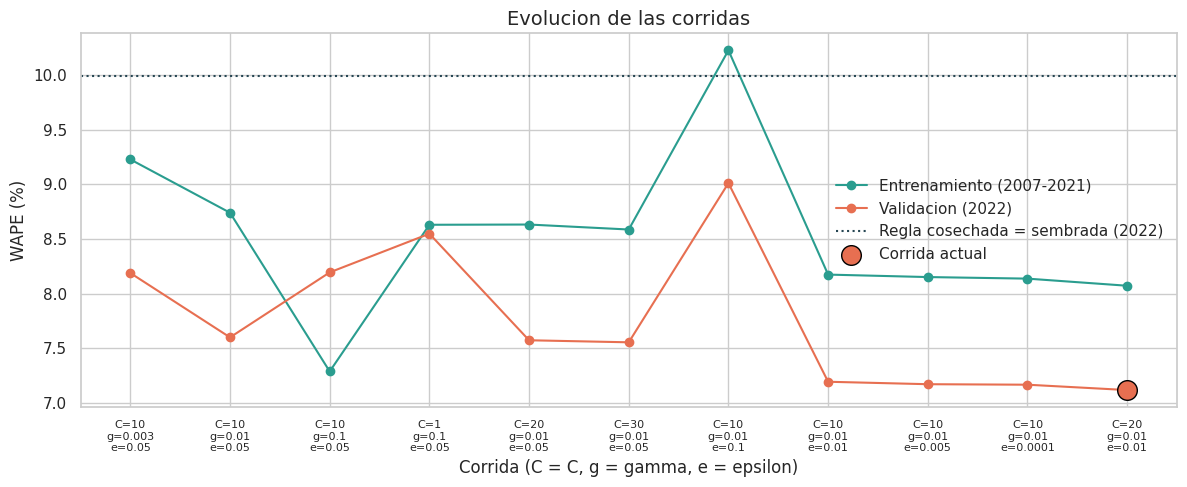

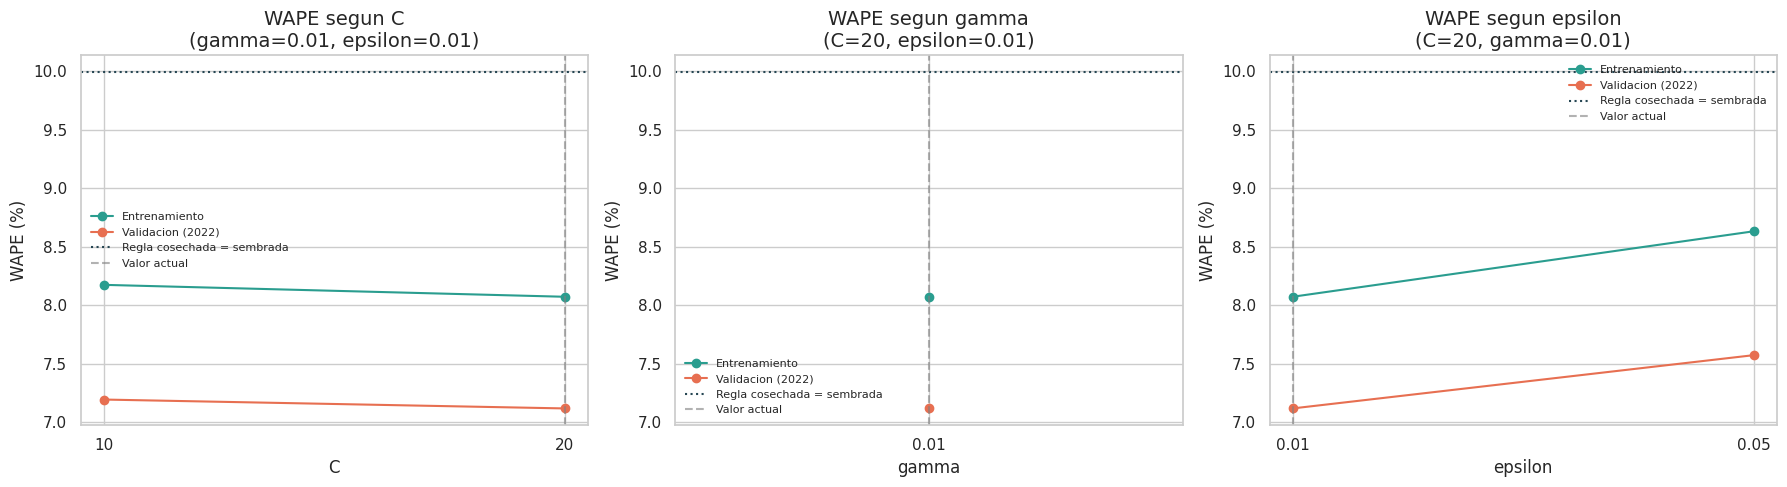

PASO F1.3: Ejecutado correctamente
-------------------------------


,C,gamma,epsilon,WAPE_entreno,WAPE_validacion,MSE_validacion,RMSE_validacion,MAE_validacion,R2_validacion,segundos
0,10,0.003,0.050,9.229,8.190,"26,627.994",163.181,25.392,0.987,22
1,10,0.010,0.050,8.741,7.601,"24,082.246",155.185,23.568,0.988,37
2,10,0.100,0.050,7.290,8.196,"30,306.726",174.088,25.411,0.985,480
3,1,0.100,0.050,8.631,8.549,"44,145.812",210.109,26.507,0.978,72
4,20,0.010,0.050,8.633,7.575,"24,122.711",155.315,23.486,0.988,59
5,30,0.010,0.050,8.588,7.556,"24,408.222",156.231,23.428,0.988,79
6,10,0.010,0.100,10.226,9.012,"27,095.006",164.606,27.942,0.986,28
7,10,0.010,0.010,8.175,7.196,"24,209.001",155.592,22.310,0.988,63
8,10,0.010,0.005,8.153,7.173,"24,163.997",155.448,22.240,0.988,71
9,10,0.010,0.000,8.139,7.169,"24,308.407",155.912,22.226,0.988,96


In [ ]:
# =========================================================
# PASO F1.3: Correr el modelo y agregarlo a las graficas
# =========================================================
print("PASO F1.3: Correr el modelo")

if REINICIAR_REGISTRO:
    registro = pd.DataFrame()
    print("Registro reiniciado")

corrida = entrenar_y_medir(C, GAMMA, EPSILON)
registro = pd.concat([registro, pd.DataFrame([corrida])], ignore_index=True)
registro.to_csv(ARCHIVO_REGISTRO, index=False)

print("Corrida", len(registro), "-> C =", C, "| gamma =", GAMMA, "| epsilon =", EPSILON)
print("WAPE entrenamiento:", round(corrida["WAPE_entreno"], 2), "% | WAPE validacion:",
      round(corrida["WAPE_validacion"], 2), "% | regla simple:", round(WAPE_REGLA_VAL, 2), "% |",
      corrida["segundos"], "s")

graficar_evolucion(registro)
graficar_un_hiperparametro(registro)

print("PASO F1.3: Ejecutado correctamente")
print("-------------------------------")
registro.round(3)

## Fase 2 — Validación

Escribir en **F2** los hiperparámetros elegidos después de las pruebas de la Fase 1. Se entrena el SVR con ellos (todas las filas de 2007–2021) y se evalúa en **2022** con las 5 métricas, comparando contra:
- el **entrenamiento**: si el error de entrenamiento es mucho menor que el de validación, hay sobreajuste;
- la **regla simple** "cosechada = sembrada": el modelo debe ganarle para aportar algo.

PASO F2: Validacion del modelo elegido
Hiperparametros: C = 10 | gamma = 0.01 | epsilon = 0.01
Tiempo: 58 s
        Entrenamiento (2007-2021)  Validacion (2022)  Regla cosechada = sembrada (2022)
MSE                    24,956.650         24,209.001                         38,212.190
RMSE                      157.977            155.592                            195.479
MAE                        27.849             22.310                             30.982
WAPE_%                      8.175              7.196                              9.993
R2                          0.986              0.988                              0.981

Diferencia de WAPE (validacion - entrenamiento): -0.98 puntos
(cerca de 0 o negativa = el modelo generaliza bien; muy positiva = sobreajuste)


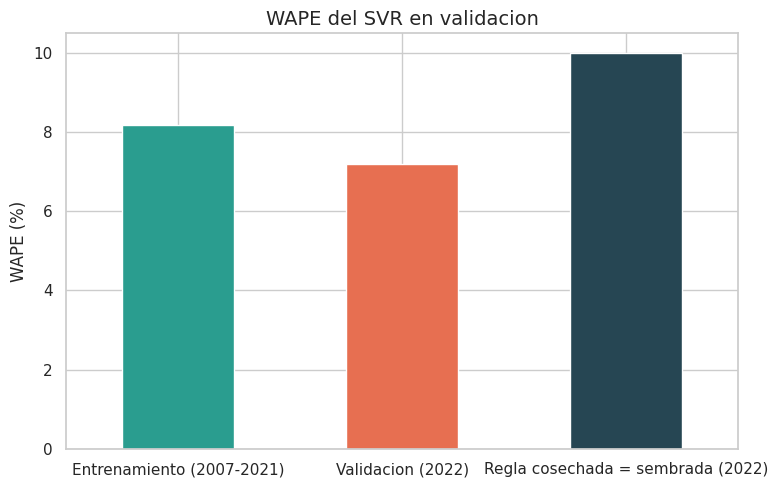

PASO F2: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO F2: Validacion del modelo elegido (2022)
# =========================================================
print("PASO F2: Validacion del modelo elegido")

# Hiperparametros elegidos en la Fase 1  (EDITAR AQUI)
C_FINAL = 10
GAMMA_FINAL = 0.01
EPSILON_FINAL = 0.01

inicio = time.time()
modelo_val = crear_modelo(C_FINAL, GAMMA_FINAL, EPSILON_FINAL)
modelo_val.fit(ent, objetivo(ent))
estimada_ent = a_hectareas(modelo_val.predict(ent), ent)
estimada_val = a_hectareas(modelo_val.predict(val), val)
print("Hiperparametros: C =", C_FINAL, "| gamma =", GAMMA_FINAL, "| epsilon =", EPSILON_FINAL)
print("Tiempo:", round(time.time() - inicio), "s")

tabla_validacion = pd.DataFrame({
    "Entrenamiento (2007-2021)": metricas(ent["area_cosechada"].values, estimada_ent),
    "Validacion (2022)": metricas(val["area_cosechada"].values, estimada_val),
    "Regla cosechada = sembrada (2022)": metricas(val["area_cosechada"].values, val["area_sembrada"].values.astype(float)),
})
print(tabla_validacion.to_string())

brecha = tabla_validacion.loc["WAPE_%", "Validacion (2022)"] - tabla_validacion.loc["WAPE_%", "Entrenamiento (2007-2021)"]
print()
print("Diferencia de WAPE (validacion - entrenamiento):", round(brecha, 2), "puntos")
print("(cerca de 0 o negativa = el modelo generaliza bien; muy positiva = sobreajuste)")

# Grafica: WAPE de entrenamiento, validacion y la regla simple
tabla_validacion.loc["WAPE_%"].plot(kind="bar", color=[VERDE, NARANJA, AZUL], figsize=(8, 5))
plt.ylabel("WAPE (%)")
plt.title("WAPE del SVR en validacion")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

tabla_validacion.to_csv(RUTA + "validacion_SVR.csv")
print("PASO F2: Ejecutado correctamente")
print("-------------------------------")

## Fase 3 — Testing

Se **reentrena** el SVR con los mejores hiperparámetros usando **2007–2022** (entrenamiento + validación) y se evalúa **una sola vez** en **2023–2025**: en total y año por año, con las 5 métricas. Los resultados se guardan en el formato común del equipo.

> No volver a cambiar hiperparámetros después de mirar estos resultados: la prueba dejaría de ser independiente.

PASO F3: Modelo final y testing
Hiperparametros: C = 10 | gamma = 0.01 | epsilon = 0.01
Tiempo: 72 s
        Entrenamiento (2007-2022)  Prueba (2023-2025)  Prueba 2023  Prueba 2024  Prueba 2025  Regla cosechada = sembrada (2023-2025)
MSE                    25,066.130          77,057.457   28,257.922   56,749.372  144,873.420                             124,230.041
RMSE                      158.323             277.592      168.101      238.221      380.622                                 352.463
MAE                        27.358              24.726       22.262       27.073       24.786                                  36.495
WAPE_%                      8.088               8.128        7.184        9.241        7.999                                  11.997
R2                          0.986               0.966        0.987        0.971        0.944                                   0.945


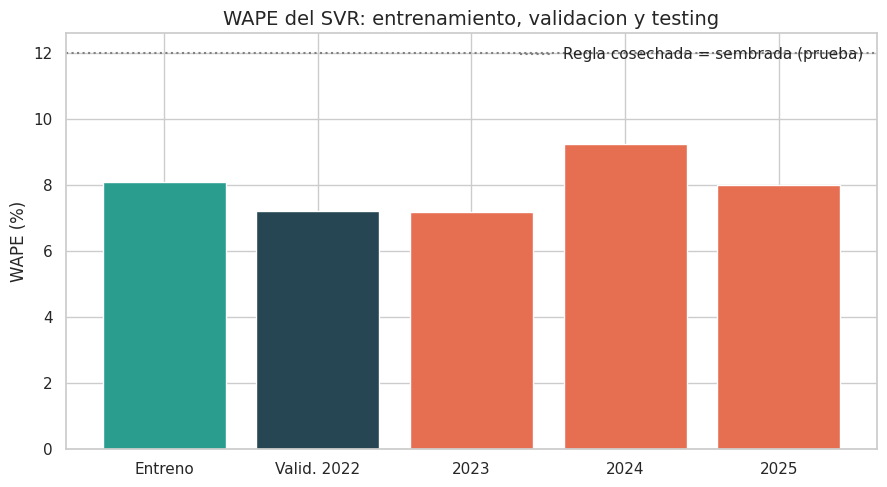

Guardados: testing_SVR.csv, resultados_SVR.csv y predicciones_SVR.csv
PASO F3: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO F3: Modelo final (2007-2022) y testing (2023-2025)
# =========================================================
print("PASO F3: Modelo final y testing")

# Entrenamiento final con 2007-2022 (el anio se topa en 2022)
entreno_final = df[df["anio"] <= ANIO_VALIDACION].copy()
ent_final = preparar(entreno_final, entreno_final, ANIO_VALIDACION)
prb = preparar(entreno_final, prueba, ANIO_VALIDACION)

inicio = time.time()
modelo_final = crear_modelo(C_FINAL, GAMMA_FINAL, EPSILON_FINAL)
modelo_final.fit(ent_final, objetivo(ent_final))
estimada_ent_final = a_hectareas(modelo_final.predict(ent_final), ent_final)
estimada_prueba = a_hectareas(modelo_final.predict(prb), prb)
print("Hiperparametros: C =", C_FINAL, "| gamma =", GAMMA_FINAL, "| epsilon =", EPSILON_FINAL)
print("Tiempo:", round(time.time() - inicio), "s")

# Metricas: entrenamiento final, prueba total, cada anio de prueba y la regla simple
columnas = {"Entrenamiento (2007-2022)": metricas(ent_final["area_cosechada"].values, estimada_ent_final),
            "Prueba (2023-2025)": metricas(prb["area_cosechada"].values, estimada_prueba)}
for anio in ANIOS_PRUEBA:
    m = (prb["anio"] == anio).values
    columnas["Prueba " + str(anio)] = metricas(prb["area_cosechada"].values[m], estimada_prueba[m])
columnas["Regla cosechada = sembrada (2023-2025)"] = metricas(prb["area_cosechada"].values,
                                                              prb["area_sembrada"].values.astype(float))
tabla_testing = pd.DataFrame(columnas)
print(tabla_testing.to_string())

# Grafica: WAPE del entrenamiento, la validacion y cada anio de prueba
etiquetas = ["Entreno", "Valid. 2022"] + [str(a) for a in ANIOS_PRUEBA]
valores = [tabla_testing.loc["WAPE_%", "Entrenamiento (2007-2022)"],
           tabla_validacion.loc["WAPE_%", "Validacion (2022)"]] + \
          [tabla_testing.loc["WAPE_%", "Prueba " + str(a)] for a in ANIOS_PRUEBA]
plt.figure(figsize=(9, 5))
plt.bar(etiquetas, valores, color=[VERDE, AZUL] + [NARANJA] * len(ANIOS_PRUEBA))
plt.axhline(tabla_testing.loc["WAPE_%", "Regla cosechada = sembrada (2023-2025)"], color="gray",
            linestyle=":", label="Regla cosechada = sembrada (prueba)")
plt.ylabel("WAPE (%)")
plt.title("WAPE del SVR: entrenamiento, validacion y testing")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

# Archivos para unificar con los otros modelos
tabla_testing.to_csv(RUTA + "testing_SVR.csv")
tabla_resultados(prb, estimada_prueba, NOMBRE_MODELO).to_csv(RUTA + "resultados_SVR.csv", index=False)
tabla_predicciones(prb, estimada_prueba, NOMBRE_MODELO).to_csv(RUTA + "predicciones_SVR.csv",
                                                               index=False, encoding="utf-8-sig")
print("Guardados: testing_SVR.csv, resultados_SVR.csv y predicciones_SVR.csv")
print("PASO F3: Ejecutado correctamente")
print("-------------------------------")

PASO F4: Graficas de resultados


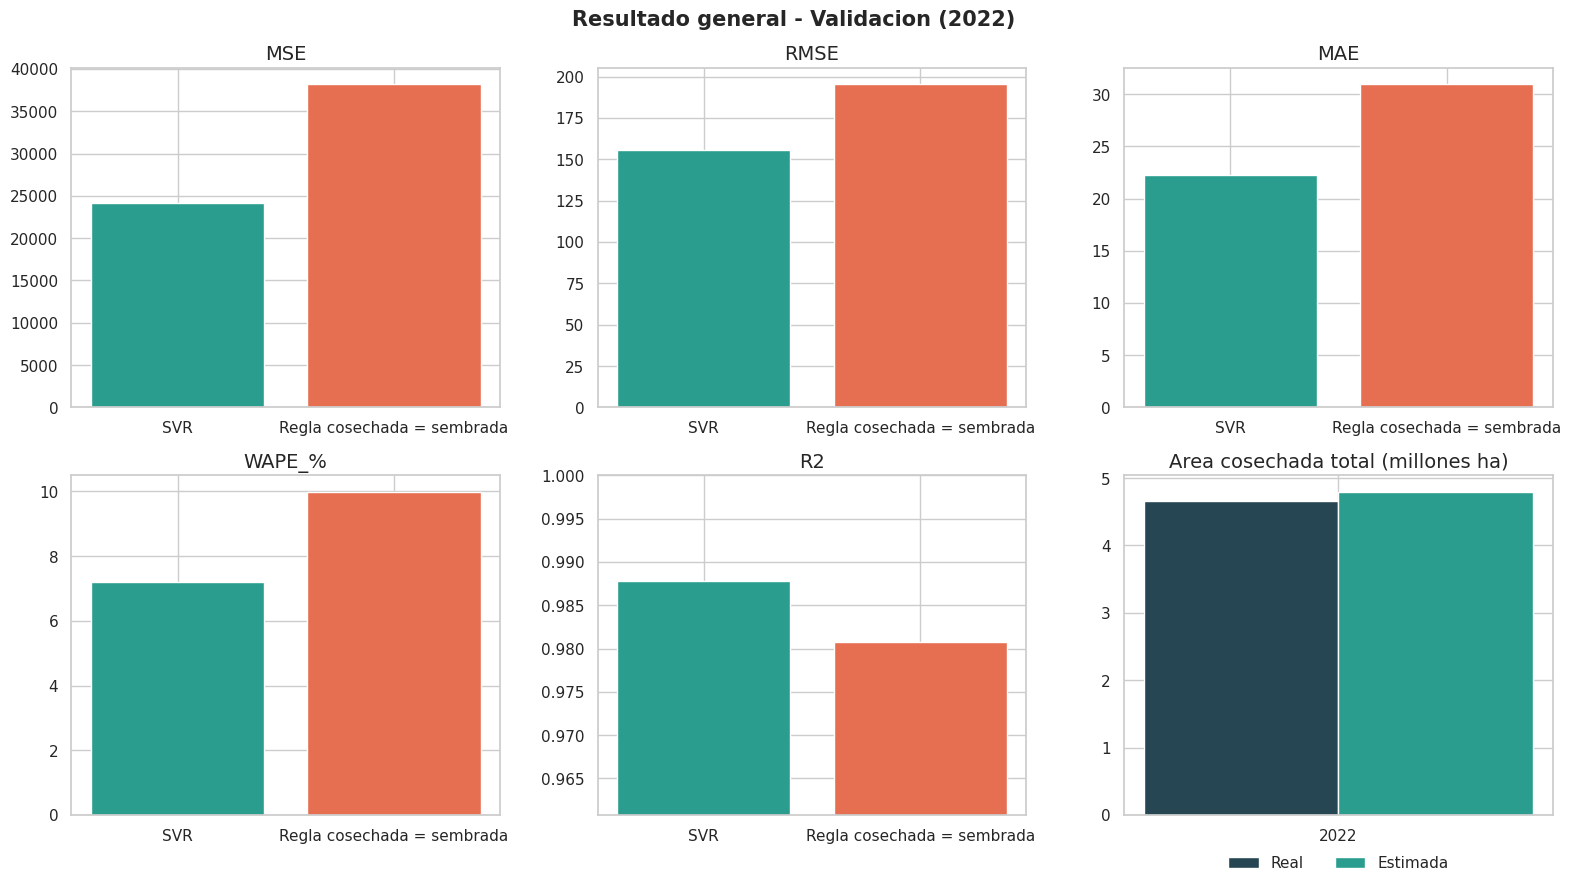

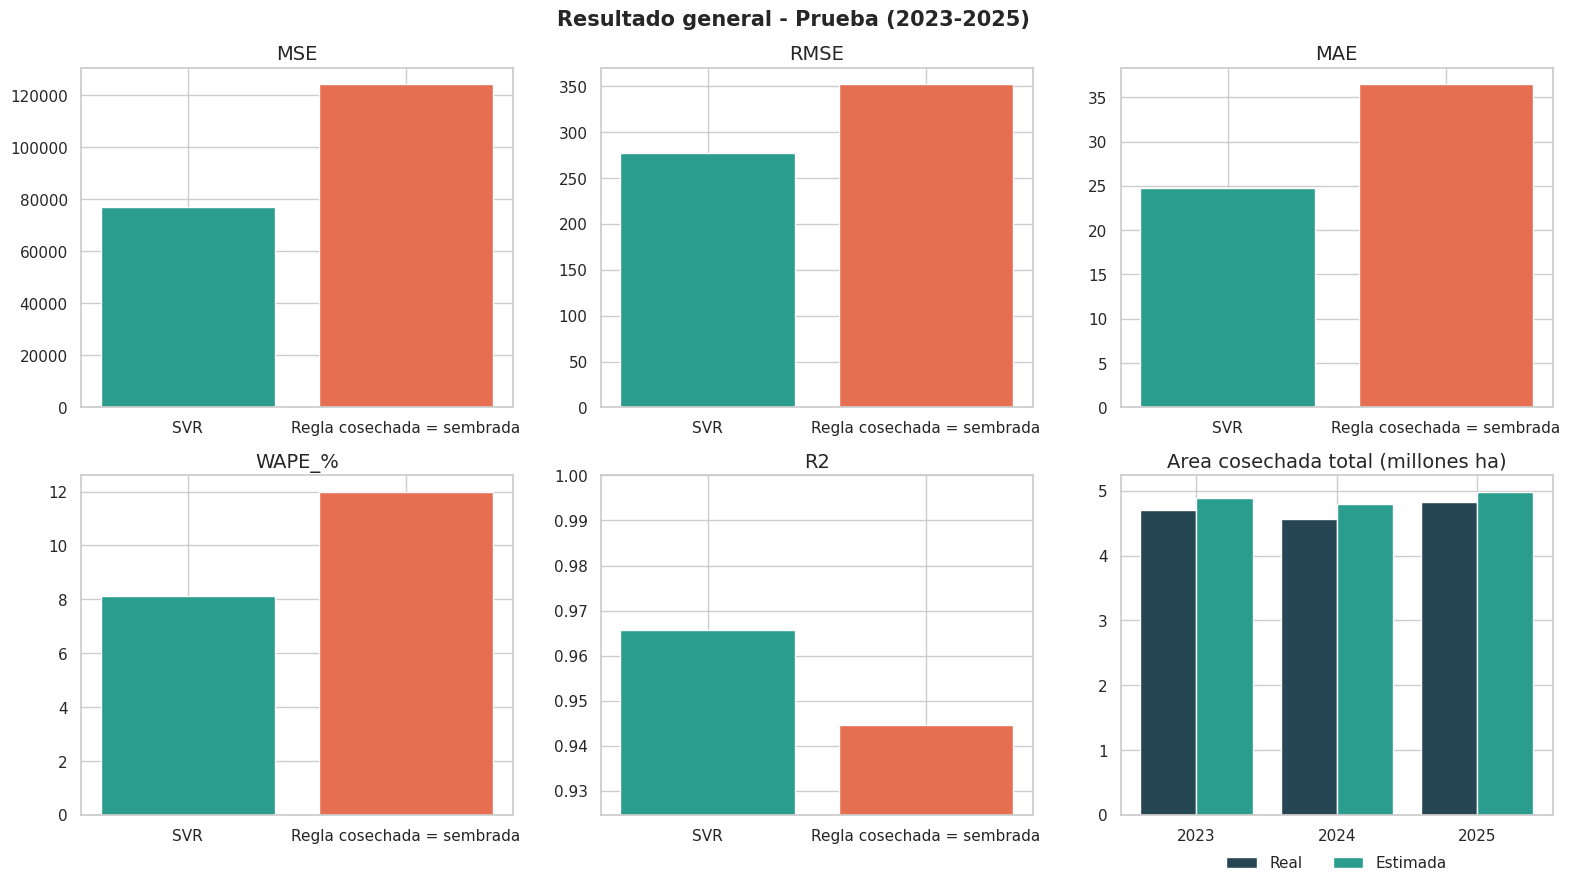

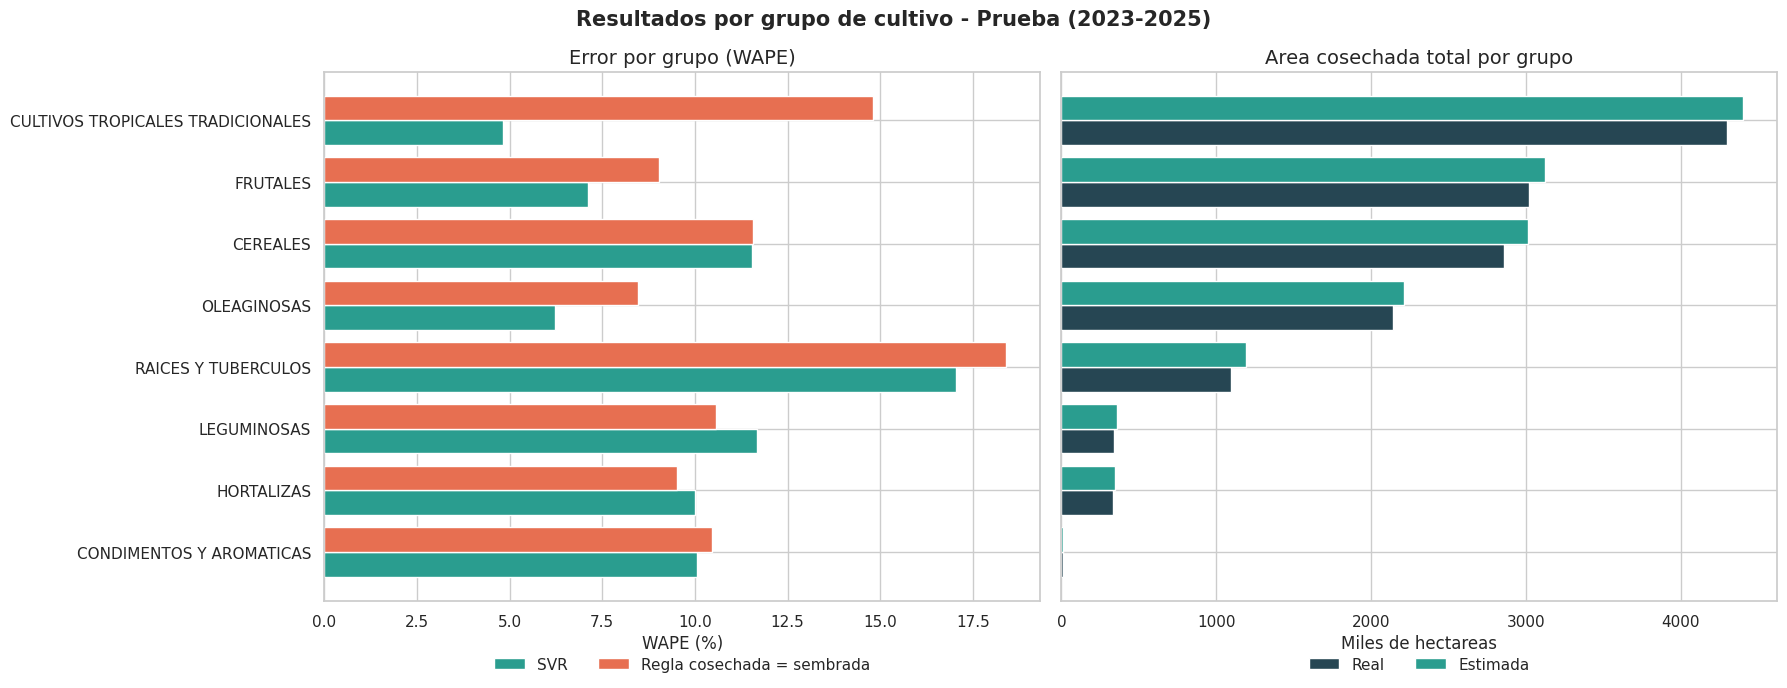

                                                             WAPE_modelo  WAPE_regla  area_cosechada      estimada
grupo                                                                                                             
CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES Y AROMATICAS       10.040      10.450      11,075.960    11,732.560
HORTALIZAS                                                        10.010       9.510     332,670.020   346,436.680
LEGUMINOSAS                                                       11.670      10.560     336,970.920   356,813.400
RAICES Y TUBERCULOS                                               17.040      18.390   1,095,539.350 1,195,329.850
OLEAGINOSAS                                                        6.220       8.460   2,141,247.210 2,213,978.780
CEREALES                                                          11.540      11.570   2,859,584.230 3,013,894.310
FRUTALES                                                           7.110       9

In [ ]:
# =========================================================
# PASO F4: Graficas de resultado general y por grupo de cultivo
# =========================================================
# Resultado general: validacion (2022) y prueba (2023-2025).
# Por grupo de cultivo: solo prueba (2023-2025).
print("PASO F4: Graficas de resultados")

def corto(grupo):
    """Nombre corto del grupo para las graficas."""
    return grupo.replace("CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES Y AROMATICAS", "CONDIMENTOS Y AROMATICAS")

def graficar_general(tabla, estimada, titulo):
    """Arriba: MSE, RMSE, MAE. Abajo: WAPE, R2 y area total por anio (modelo vs regla simple)."""
    real = tabla["area_cosechada"].values
    m_mod = metricas(real, estimada)
    m_reg = metricas(real, tabla["area_sembrada"].values.astype(float))
    figura, ejes = plt.subplots(2, 3, figsize=(16, 9))
    for ax, n in zip([ejes[0, 0], ejes[0, 1], ejes[0, 2], ejes[1, 0], ejes[1, 1]],
                     ["MSE", "RMSE", "MAE", "WAPE_%", "R2"]):
        ax.bar([NOMBRE_MODELO, "Regla cosechada = sembrada"], [m_mod[n], m_reg[n]], color=[VERDE, NARANJA])
        ax.set_title(n)
        if n == "R2":
            ax.set_ylim(min(m_mod[n], m_reg[n]) - 0.02, 1)
    # Area cosechada total por anio: real vs estimada
    t = pd.DataFrame({"anio": tabla["anio"].values, "real": real, "estimada": estimada}).groupby("anio").sum() / 1e6
    x = np.arange(len(t))
    ax = ejes[1, 2]
    ax.bar(x - 0.2, t["real"], 0.4, color=AZUL, label="Real")
    ax.bar(x + 0.2, t["estimada"], 0.4, color=VERDE, label="Estimada")
    ax.set_xticks(x); ax.set_xticklabels(t.index)
    ax.set_title("Area cosechada total (millones ha)")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
    figura.suptitle(titulo, fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()

def graficar_por_grupo(tabla, estimada, titulo):
    """Por grupo: WAPE (modelo vs regla simple) y area cosechada total (real vs estimada)."""
    t = tabla[["grupo", "area_sembrada", "area_cosechada"]].copy()
    t["estimada"] = estimada
    t["error_modelo"] = (t["estimada"] - t["area_cosechada"]).abs()
    t["error_regla"] = (t["area_sembrada"] - t["area_cosechada"]).abs()
    g = t.groupby("grupo")[["area_cosechada", "estimada", "error_modelo", "error_regla"]].sum()
    g["WAPE_modelo"] = g["error_modelo"] / g["area_cosechada"] * 100
    g["WAPE_regla"] = g["error_regla"] / g["area_cosechada"] * 100
    g = g.sort_values("area_cosechada")

    y = np.arange(len(g))
    alto = 0.4
    figura, ejes = plt.subplots(1, 2, figsize=(18, 7))
    # 1) WAPE por grupo
    ejes[0].barh(y - alto / 2, g["WAPE_modelo"], alto, color=VERDE, label=NOMBRE_MODELO)
    ejes[0].barh(y + alto / 2, g["WAPE_regla"], alto, color=NARANJA, label="Regla cosechada = sembrada")
    ejes[0].set_yticks(y); ejes[0].set_yticklabels([corto(n) for n in g.index])
    ejes[0].set_xlabel("WAPE (%)"); ejes[0].set_title("Error por grupo (WAPE)")
    ejes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
    # 2) Area cosechada total por grupo
    ejes[1].barh(y - alto / 2, g["area_cosechada"] / 1000, alto, color=AZUL, label="Real")
    ejes[1].barh(y + alto / 2, g["estimada"] / 1000, alto, color=VERDE, label="Estimada")
    ejes[1].set_yticks(y); ejes[1].set_yticklabels([])
    ejes[1].set_xlabel("Miles de hectareas"); ejes[1].set_title("Area cosechada total por grupo")
    ejes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
    figura.suptitle(titulo, fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()
    print(g[["WAPE_modelo", "WAPE_regla", "area_cosechada", "estimada"]].round(2).to_string())

graficar_general(val, estimada_val, "Resultado general - Validacion (2022)")
graficar_general(prb, estimada_prueba, "Resultado general - Prueba (2023-2025)")
graficar_por_grupo(prb, estimada_prueba, "Resultados por grupo de cultivo - Prueba (2023-2025)")
print("PASO F4: Ejecutado correctamente")
print("-------------------------------")